# Ejercicio 2: Clasificación estadística de patrones

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 2 de la guía, que recorre el problema de clasificación desde un caso puramente geométrico hasta un clasificador gaussiano cuyos parámetros se estiman a partir de datos.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Clasificador geométrico lineal con $g_1,g_2,g_3$: fronteras, regiones y clasificación de 4 puntos | Regla $\arg\max_i g_i(\mathbf{x})$; fronteras = hiperplanos |
| **2** | Dos clases gaussianas equiprobables con $\boldsymbol{\Sigma}=\mathbf{I}$: construir el clasificador y hallar la frontera | Regla de Bayes $\to$ mínima distancia euclídea |
| **3** | Clasificador gaussiano por máxima verosimilitud sobre un mini-corpus: tasa de aciertos y evaluación con datos nuevos | Estimación ML de $\boldsymbol{\mu}_i,\boldsymbol{\Sigma}_i,P(\omega_i)$ + modelo generativo |

**Contenido**

1. [Clasificador geométrico lineal](#1.-Clasificador-geométrico-lineal)
2. [Clasificador gaussiano de dos clases](#2.-Clasificador-gaussiano-de-dos-clases)
3. [Clasificador gaussiano por máxima verosimilitud](#3.-Clasificador-gaussiano-por-máxima-verosimilitud)
4. [Conclusiones](#4.-Conclusiones)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import norm, multivariate_normal

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

---
## 1. Clasificador geométrico lineal

> *Sea un clasificador geométrico lineal definido por $g_1(\mathbf{x})=-x_1$, $g_2(\mathbf{x})=x_1+x_2-1$, $g_3(\mathbf{x})=x_1-x_2-1$.*
> *a) Calcule y grafique las fronteras y regiones de decisión. b) Clasifique los puntos $(2,1)$; $(2,-1)$; $(-1,1)$; $(-1,-1)$.*

### 1.1 Marco teórico

Un clasificador de $C$ clases puede describirse mediante **funciones discriminantes** $g_1(\mathbf{x}),\dots,g_C(\mathbf{x})$ con la regla

$$
\mathbf{x}\in\mathcal{R}_i \iff g_i(\mathbf{x}) > g_j(\mathbf{x})\quad\forall j\neq i
\qquad\Longleftrightarrow\qquad \hat{\omega}(\mathbf{x})=\arg\max_i\, g_i(\mathbf{x}).
$$

- Las **regiones de decisión** $\mathcal{R}_i$ son los conjuntos de puntos donde gana la clase $i$.
- Las **fronteras de decisión** son los puntos donde dos discriminantes empatan: $g_i(\mathbf{x})=g_j(\mathbf{x})$. Solo forman parte de la frontera real los puntos donde ese empate corresponde al **máximo** (es decir, ningún tercer discriminante es mayor).

El clasificador es **lineal** cuando $g_i(\mathbf{x})=\mathbf{w}_i^\top\mathbf{x}+b_i$. En ese caso la frontera entre $i$ y $j$ es

$$
(\mathbf{w}_i-\mathbf{w}_j)^\top\mathbf{x}+(b_i-b_j)=0,
$$

un **hiperplano** (una recta en 2D), y cada región es una intersección de semiplanos (una región convexa).

### 1.2 a) Fronteras y regiones de decisión

Se calculan las tres igualdades posibles:

| Frontera | Condición | Recta |
|:--|:--|:--|
| $g_1=g_2$ | $-x_1 = x_1+x_2-1$ | $x_2 = 1-2x_1$ |
| $g_1=g_3$ | $-x_1 = x_1-x_2-1$ | $x_2 = 2x_1-1$ |
| $g_2=g_3$ | $x_1+x_2-1 = x_1-x_2-1$ | $x_2 = 0$ |

Las tres rectas se cortan en un único punto: de $g_2=g_3$ resulta $x_2=0$, y reemplazando en $g_1=g_2$, $2x_1=1$, o sea $\mathbf{x}^*=(0.5,\,0)$. En ese punto $g_1=g_2=g_3=-0.5$.

Como las tres rectas pasan por $\mathbf{x}^*$, el plano queda dividido en **tres cuñas** (cada recta aporta una semirrecta como frontera real y descarta la otra). Las regiones se obtienen de las desigualdades:

- $\mathcal{R}_1$: $g_1>g_2$ y $g_1>g_3$ $\iff$ $2x_1+x_2<1$ y $x_2>2x_1-1$ (cuña de la izquierda).
- $\mathcal{R}_2$: $g_2>g_1$ y $g_2>g_3$ $\iff$ $2x_1+x_2>1$ y $x_2>0$ (cuña de arriba).
- $\mathcal{R}_3$: $g_3>g_1$ y $g_3>g_2$ $\iff$ $x_2<2x_1-1$ y $x_2<0$ (cuña de abajo).

Verificamos y graficamos numéricamente. Se escribe cada discriminante como $\mathbf{w}_i^\top\mathbf{x}+b_i$ y se evalúa el $\arg\max$ sobre una grilla. Para dibujar las fronteras se toma cada recta $g_i=g_j$ pero **solo se conserva el tramo donde el empate es el máximo**.

In [2]:
# g_i(x) = w_i . x + b_i
W = np.array([[-1.0,  0.0],     # g1 = -x1
              [ 1.0,  1.0],     # g2 = x1 + x2 - 1
              [ 1.0, -1.0]])    # g3 = x1 - x2 - 1
b = np.array([0.0, -1.0, -1.0])


def g_lineal(X):
    '''Evalúa los 3 discriminantes en cada fila de X. Devuelve (N, 3).'''
    return X @ W.T + b


def clasificar_lineal(X):
    return np.argmax(g_lineal(X), axis=1) + 1        # clases 1, 2, 3


# Punto de intersección de las tres fronteras: resolver g1 = g2 y g2 = g3
A_sis = np.array([W[0] - W[1], W[1] - W[2]])
b_sis = -np.array([b[0] - b[1], b[1] - b[2]])
x_star = np.linalg.solve(A_sis, b_sis)
print("Punto de intersección de las fronteras:", x_star)
print("g1, g2, g3 en ese punto:", g_lineal(x_star[None, :])[0])

Punto de intersección de las fronteras: [ 0.5 -0. ]
g1, g2, g3 en ese punto: [-0.5 -0.5 -0.5]


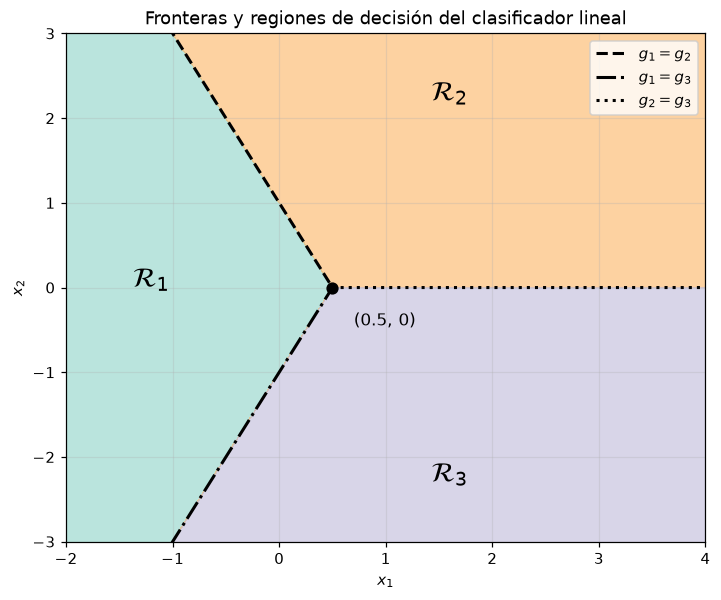

In [3]:
xlim, ylim = (-2, 4), (-3, 3)
xx, yy = np.meshgrid(np.linspace(*xlim, 600), np.linspace(*ylim, 600))
grilla = np.c_[xx.ravel(), yy.ravel()]
regiones = clasificar_lineal(grilla).reshape(xx.shape)

colores = ["#8dd3c7", "#fdb462", "#bebada"]
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contourf(xx, yy, regiones, levels=[0.5, 1.5, 2.5, 3.5], colors=colores, alpha=0.6)

# Fronteras: para cada par (i, j) se recorre la recta g_i = g_j y se conserva el tramo
# donde ese empate es el máximo de los tres discriminantes.
x1_lin = np.linspace(*xlim, 2000)
estilos = {(0, 1): ("k--", "$g_1=g_2$"), (0, 2): ("k-.", "$g_1=g_3$"), (1, 2): ("k:", "$g_2=g_3$")}
for (i, j), (estilo, etiqueta) in estilos.items():
    dw, db = W[i] - W[j], b[i] - b[j]
    x2_lin = -(dw[0] * x1_lin + db) / dw[1] if dw[1] != 0 else None     # despeja x2 (dw[1] != 0 acá)
    pts = np.c_[x1_lin, x2_lin]
    G = g_lineal(pts)
    k = ({0, 1, 2} - {i, j}).pop()
    valido = G[:, i] >= G[:, k] - 1e-9                # el empate i=j es el máximo
    ax.plot(x1_lin[valido], np.where(valido, x2_lin, np.nan)[valido], estilo, lw=2, label=etiqueta)

ax.plot(*x_star, "ko", ms=7)
ax.annotate("$(0.5,\\,0)$", x_star, xytext=(0.7, -0.45), fontsize=11)
for txt, pos in zip(["$\\mathcal{R}_1$", "$\\mathcal{R}_2$", "$\\mathcal{R}_3$"], [(-1.2, 0), (1.6, 2.2), (1.6, -2.3)]):
    ax.text(*pos, txt, fontsize=18, ha="center")

ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Fronteras y regiones de decisión del clasificador lineal")
ax.legend(loc="upper right")
plt.show()

### 1.3 b) Clasificación de los puntos

Para cada punto se evalúan los tres discriminantes y se elige el máximo.

In [4]:
puntos = np.array([[2, 1], [2, -1], [-1, 1], [-1, -1]], dtype=float)
G = g_lineal(puntos)
clases_pred = clasificar_lineal(puntos)

print(f"{'punto':>9} |    g1 |    g2 |    g3 | clase")
print("-" * 44)
for p, g, c in zip(puntos, G, clases_pred):
    print(f"({p[0]:>3.0f},{p[1]:>3.0f}) | {g[0]:5.1f} | {g[1]:5.1f} | {g[2]:5.1f} |   {c}")

    punto |    g1 |    g2 |    g3 | clase
--------------------------------------------
(  2,  1) |  -2.0 |   2.0 |   0.0 |   2
(  2, -1) |  -2.0 |   0.0 |   2.0 |   3
( -1,  1) |   1.0 |  -1.0 |  -3.0 |   1
( -1, -1) |   1.0 |  -3.0 |  -1.0 |   1


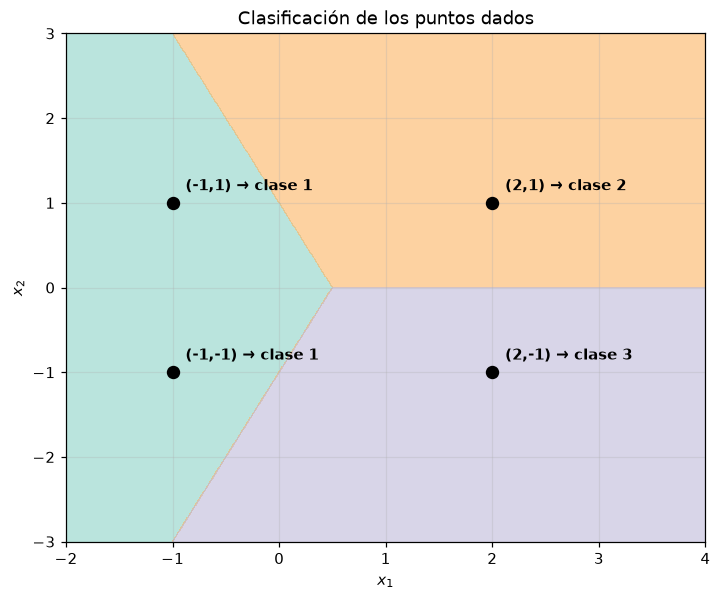

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contourf(xx, yy, regiones, levels=[0.5, 1.5, 2.5, 3.5], colors=colores, alpha=0.6)
ax.scatter(puntos[:, 0], puntos[:, 1], c="k", s=60, zorder=5)
for p, c in zip(puntos, clases_pred):
    ax.annotate(f"({p[0]:.0f},{p[1]:.0f}) → clase {c}", p, xytext=(p[0] + 0.12, p[1] + 0.15),
                fontsize=10, fontweight="bold")
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Clasificación de los puntos dados")
plt.show()

**Resultado.**

| Punto | $g_1$ | $g_2$ | $g_3$ | Clase |
|:--|:--:|:--:|:--:|:--:|
| $(2,\,1)$ | $-2$ | $\mathbf{2}$ | $0$ | $\omega_2$ |
| $(2,\,-1)$ | $-2$ | $0$ | $\mathbf{2}$ | $\omega_3$ |
| $(-1,\,1)$ | $\mathbf{1}$ | $-1$ | $-3$ | $\omega_1$ |
| $(-1,\,-1)$ | $\mathbf{1}$ | $-3$ | $-1$ | $\omega_1$ |

Los resultados coinciden con la ubicación de cada punto en el gráfico: los dos puntos con $x_1=-1$ caen en la cuña izquierda ($\mathcal{R}_1$), y los dos con $x_1=2$ quedan separados por la recta $x_2=0$ entre $\mathcal{R}_2$ (arriba) y $\mathcal{R}_3$ (abajo).

---
## 2. Clasificador gaussiano de dos clases

> *Sean $A$ y $B$ dos clases de igual probabilidad a priori definidas por $P(\mathbf{x}|A)\sim\mathcal{N}\!\left(\binom{3}{0},\mathbf{I}\right)$ y $P(\mathbf{x}|B)\sim\mathcal{N}\!\left(\binom{0}{3},\mathbf{I}\right)$.*
> *a) Construya un clasificador gaussiano y encuentre la frontera. b) Realice una representación gráfica del problema.*

### 2.1 Marco teórico: clasificador de Bayes con clases gaussianas

La regla de decisión óptima (**mínimo error de clasificación**) asigna $\mathbf{x}$ a la clase de mayor probabilidad a posteriori, $P(\omega_i|\mathbf{x})\propto p(\mathbf{x}|\omega_i)P(\omega_i)$ (teorema de Bayes). Tomando logaritmo (función monótona creciente, no altera el $\arg\max$), se pueden usar los discriminantes

$$
g_i(\mathbf{x}) = \ln p(\mathbf{x}|\omega_i)+\ln P(\omega_i).
$$

Si $p(\mathbf{x}|\omega_i)=\mathcal{N}(\boldsymbol{\mu}_i,\boldsymbol{\Sigma}_i)$, y descartando el término $-\frac{d}{2}\ln 2\pi$, común a todas las clases:

$$
g_i(\mathbf{x}) = -\tfrac12(\mathbf{x}-\boldsymbol{\mu}_i)^\top\boldsymbol{\Sigma}_i^{-1}(\mathbf{x}-\boldsymbol{\mu}_i)-\tfrac12\ln|\boldsymbol{\Sigma}_i|+\ln P(\omega_i).
$$

Según la estructura de las covarianzas aparecen tres casos:

| Caso | Covarianzas | Discriminante / frontera |
|:--|:--|:--|
| **1** | $\boldsymbol{\Sigma}_i=\sigma^2\mathbf{I}$ | Lineal. Con priors iguales: **mínima distancia euclídea** a las medias. Frontera: hiperplano perpendicular al segmento que une las medias. |
| **2** | $\boldsymbol{\Sigma}_i=\boldsymbol{\Sigma}$ (igual para todas) | Lineal. Con priors iguales: **mínima distancia de Mahalanobis**. Hiperplano, en general no perpendicular al segmento entre medias. |
| **3** | $\boldsymbol{\Sigma}_i$ arbitrarias | **Cuadrática** (hipercuádricas: rectas, elipses, parábolas, hipérbolas). |

Para dos clases en los casos 1 y 2 la frontera $g_A(\mathbf{x})=g_B(\mathbf{x})$ es

$$
\mathbf{w}^\top(\mathbf{x}-\mathbf{x}_0)=0,\qquad
\mathbf{w}=\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B),\qquad
\mathbf{x}_0=\tfrac12(\boldsymbol{\mu}_A+\boldsymbol{\mu}_B)-\frac{\ln\frac{P(A)}{P(B)}}{(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)^\top\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)}\,(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B).
$$

Con **priors iguales**, el segundo término se anula y la frontera pasa por el **punto medio** de las medias.

### 2.2 a) Resolución analítica

Con $\boldsymbol{\Sigma}=\mathbf{I}$, $P(A)=P(B)$, $\boldsymbol{\mu}_A=(3,0)^\top$ y $\boldsymbol{\mu}_B=(0,3)^\top$:

- $\mathbf{w}=\mathbf{I}^{-1}(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)=(3,\,-3)^\top$
- $\mathbf{x}_0=\tfrac12(\boldsymbol{\mu}_A+\boldsymbol{\mu}_B)=(1.5,\,1.5)^\top$

La frontera es $3(x_1-1.5)-3(x_2-1.5)=0\iff \boxed{x_1=x_2}$, la **mediatriz** del segmento entre las medias.

Alternativamente, igualando discriminantes (los términos $\ln|\mathbf{I}|$ y $\ln P$ se cancelan):
$\|\mathbf{x}-\boldsymbol{\mu}_A\|^2=\|\mathbf{x}-\boldsymbol{\mu}_B\|^2\Rightarrow -6x_1+9=-6x_2+9\Rightarrow x_1=x_2$.

La regla resulta: **$\mathbf{x}\to A$ si $x_1>x_2$, $\mathbf{x}\to B$ si $x_1<x_2$**.

**Error de Bayes.** Al proyectar sobre la dirección de $\mathbf{w}$, cada clase es una gaussiana unidimensional de varianza 1 y las medias quedan a una distancia $\Delta=\sqrt{(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)^\top\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_A-\boldsymbol{\mu}_B)}=\sqrt{18}\approx4.24$ (distancia de Mahalanobis). Con priors iguales, el umbral está a $\Delta/2$ de cada media, por lo que

$$
P(\text{error})=\Phi\!\left(-\frac{\Delta}{2}\right)=\Phi(-2.12)\approx 0.017.
$$

### 2.3 Implementación del clasificador gaussiano

Se implementa una clase general `ClasificadorGaussiano` con los discriminantes cuadráticos (caso 3), que incluye a los casos 1 y 2 como situaciones particulares. Se reutilizará en el inciso 3 con parámetros estimados.

In [6]:
class ClasificadorGaussiano:
    '''Clasificador de Bayes con verosimilitudes gaussianas N(mu_i, Sigma_i) y priors P(w_i).'''

    def __init__(self, medias, covarianzas, priors, etiquetas=None):
        self.mu = np.asarray(medias, float)                 # (C, d)
        self.Sigma = np.asarray(covarianzas, float)         # (C, d, d)
        self.prior = np.asarray(priors, float)              # (C,)
        self.etiquetas = np.arange(len(self.mu)) if etiquetas is None else np.asarray(etiquetas)

    @classmethod
    def desde_datos(cls, X, y, ddof=0):
        '''Estimación por máxima verosimilitud de mu_i, Sigma_i y P(w_i) (ddof=0 -> estimador ML).'''
        etiquetas = np.unique(y)
        medias, covs, priors = [], [], []
        for c in etiquetas:
            Xc = X[y == c]
            medias.append(Xc.mean(axis=0))
            covs.append(np.cov(Xc, rowvar=False, ddof=ddof))
            priors.append(len(Xc) / len(X))
        return cls(medias, covs, priors, etiquetas)

    def discriminantes(self, X):
        '''g_i(x) = -1/2 (x-mu_i)^T Sigma_i^-1 (x-mu_i) - 1/2 ln|Sigma_i| + ln P(w_i). Devuelve (N, C).'''
        G = np.empty((len(X), len(self.mu)))
        for i in range(len(self.mu)):
            dif = X - self.mu[i]
            mahal2 = np.einsum("nj,jk,nk->n", dif, np.linalg.inv(self.Sigma[i]), dif)
            _, logdet = np.linalg.slogdet(self.Sigma[i])
            G[:, i] = -0.5 * mahal2 - 0.5 * logdet + np.log(self.prior[i])
        return G

    def predecir(self, X):
        return self.etiquetas[np.argmax(self.discriminantes(X), axis=1)]

    def posteriori(self, X):
        '''P(w_i | x) = softmax de los discriminantes.'''
        G = self.discriminantes(X)
        G -= G.max(axis=1, keepdims=True)                   # estabilidad numérica
        P = np.exp(G)
        return P / P.sum(axis=1, keepdims=True)

    def muestrear(self, N, rng):
        '''Genera N muestras del modelo generativo: primero la clase ~ P(w_i), luego x ~ N(mu_i, Sigma_i).'''
        cuentas = rng.multinomial(N, self.prior)
        X = np.vstack([rng.multivariate_normal(self.mu[i], self.Sigma[i], n) for i, n in enumerate(cuentas)])
        y = np.concatenate([np.full(n, self.etiquetas[i]) for i, n in enumerate(cuentas)])
        return X, y


def elipse_sigma(mu, Sigma, k, n=200):
    '''Puntos de la elipse de k desvíos: {x : (x-mu)^T Sigma^-1 (x-mu) = k^2}.'''
    lam, V = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2 * np.pi, n)
    return (np.asarray(mu)[:, None] + k * V @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(t), np.sin(t)]))).T

In [7]:
mu_A, mu_B = np.array([3.0, 0.0]), np.array([0.0, 3.0])
clf_AB = ClasificadorGaussiano(medias=[mu_A, mu_B], covarianzas=[np.eye(2), np.eye(2)],
                               priors=[0.5, 0.5], etiquetas=["A", "B"])

# --- Frontera analítica: w^T (x - x0) = 0 ---
w = np.linalg.inv(np.eye(2)) @ (mu_A - mu_B)
x0 = 0.5 * (mu_A + mu_B)                                   # priors iguales -> punto medio
print("w  =", w, "  x0 =", x0)

# --- Verificación numérica: el clasificador debe coincidir con la regla "x1 > x2 -> A" ---
xx2, yy2 = np.meshgrid(np.linspace(-3, 6, 600), np.linspace(-3, 6, 600))
grilla2 = np.c_[xx2.ravel(), yy2.ravel()]
pred = clf_AB.predecir(grilla2)
regla = np.where(grilla2[:, 0] > grilla2[:, 1], "A", "B")
sin_empate = np.abs(grilla2[:, 0] - grilla2[:, 1]) > 1e-9        # se excluyen los puntos exactamente sobre la frontera
print(f"Coincidencia con la regla x1 > x2 en la grilla: {np.mean(pred[sin_empate] == regla[sin_empate]) * 100:.2f}% "
      f"de los {sin_empate.sum()} puntos fuera de la frontera")

w  = [ 3. -3.]   x0 = [1.5 1.5]
Coincidencia con la regla x1 > x2 en la grilla: 100.00% de los 359400 puntos fuera de la frontera


### 2.4 b) Representación gráfica

Se muestran, a la izquierda, las curvas de nivel de ambas densidades ($1\sigma$, $2\sigma$, $3\sigma$), una muestra aleatoria de cada clase y la frontera de decisión. A la derecha, la probabilidad a posteriori $P(A|\mathbf{x})$, que vale $0.5$ exactamente sobre la frontera.

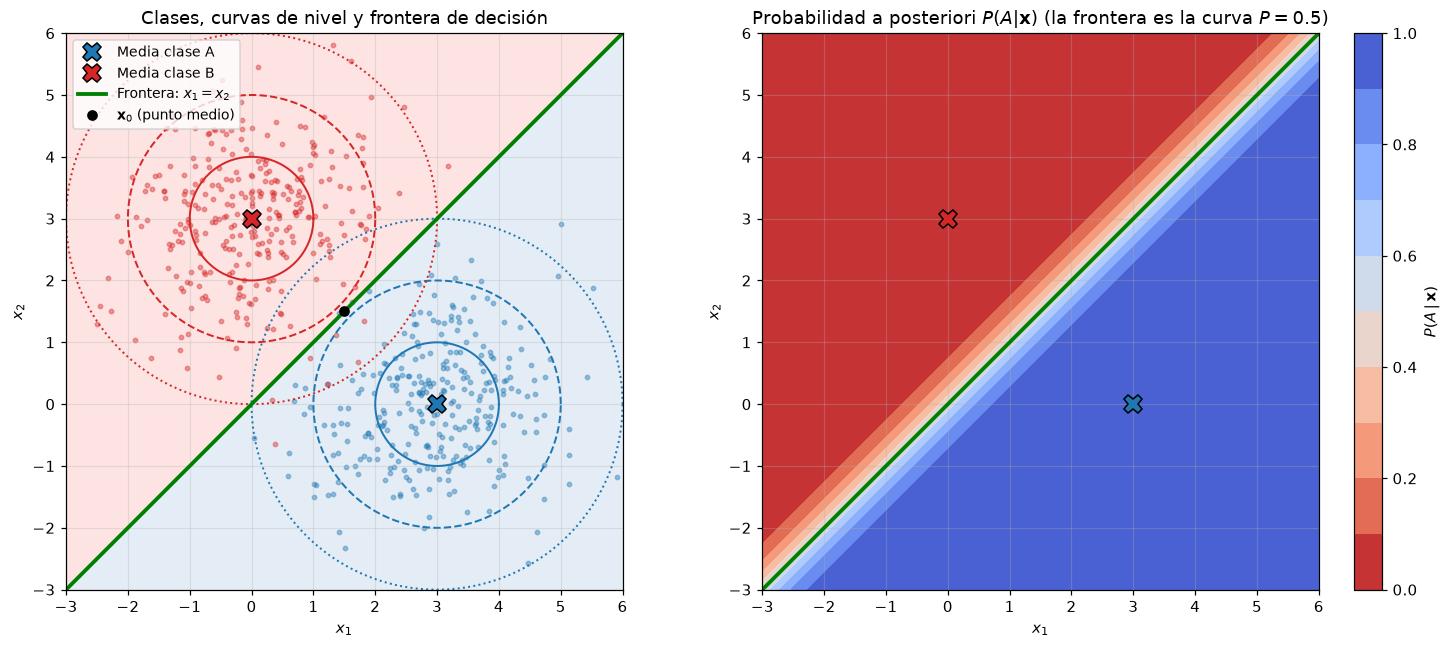

In [8]:
X_AB, y_AB = clf_AB.muestrear(600, rng)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Izquierda: densidades, muestras y frontera ---
ax1.contourf(xx2, yy2, (pred == "A").reshape(xx2.shape).astype(float), levels=[-0.5, 0.5, 1.5],
             colors=["#fbb4ae", "#b3cde3"], alpha=0.35)
for clase, mu, c in [("A", mu_A, "tab:blue"), ("B", mu_B, "tab:red")]:
    ax1.scatter(*X_AB[y_AB == clase].T, s=8, alpha=0.4, color=c)
    for k, ls in zip([1, 2, 3], ["-", "--", ":"]):
        e = elipse_sigma(mu, np.eye(2), k)
        ax1.plot(e[:, 0], e[:, 1], color=c, ls=ls, lw=1.3)
    ax1.plot(*mu, "X", color=c, ms=12, mec="k", label=f"Media clase {clase}")
ax1.plot([-3, 6], [-3, 6], "g-", lw=2.5, label="Frontera: $x_1=x_2$")
ax1.plot(*x0, "ko", ms=6, label="$\\mathbf{x}_0$ (punto medio)")
ax1.set_title("Clases, curvas de nivel y frontera de decisión")

# --- Derecha: probabilidad a posteriori de A ---
post_A = clf_AB.posteriori(grilla2)[:, 0].reshape(xx2.shape)
im = ax2.contourf(xx2, yy2, post_A, levels=np.linspace(0, 1, 11), cmap="coolwarm_r")
fig.colorbar(im, ax=ax2, label="$P(A\\,|\\,\\mathbf{x})$")
ax2.contour(xx2, yy2, post_A, levels=[0.5], colors="g", linewidths=2.5)
ax2.plot(*mu_A, "X", color="tab:blue", ms=12, mec="k"); ax2.plot(*mu_B, "X", color="tab:red", ms=12, mec="k")
ax2.set_title("Probabilidad a posteriori $P(A|\\mathbf{x})$ (la frontera es la curva $P=0.5$)")

for ax in (ax1, ax2):
    ax.set_xlim(-3, 6); ax.set_ylim(-3, 6); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax1.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

### 2.5 Verificación del error de Bayes

Se compara el error teórico $\Phi(-\Delta/2)$ con el error empírico del clasificador sobre una muestra grande.

In [9]:
delta = np.sqrt((mu_A - mu_B) @ np.linalg.inv(np.eye(2)) @ (mu_A - mu_B))
err_teorico = norm.cdf(-delta / 2)

X_big, y_big = clf_AB.muestrear(500_000, rng)
err_empirico = np.mean(clf_AB.predecir(X_big) != y_big)

print(f"Distancia de Mahalanobis entre medias  Δ = {delta:.4f}")
print(f"Error de Bayes teórico   Φ(-Δ/2)         = {err_teorico:.5f}")
print(f"Error empírico (N = 500 000)              = {err_empirico:.5f}")

Distancia de Mahalanobis entre medias  Δ = 4.2426
Error de Bayes teórico   Φ(-Δ/2)         = 0.01695
Error empírico (N = 500 000)              = 0.01710


**Observaciones.**

- La frontera hallada analíticamente, $x_1=x_2$, coincide exactamente con la que produce el clasificador general (cuadrático) implementado, lo que valida tanto el cálculo a mano como el código.
- Las nubes son circulares y de igual tamaño, por lo que el clasificador de Bayes se reduce a un clasificador de **mínima distancia euclídea**: un punto se asigna a la media más cercana.
- La probabilidad a posteriori es una **sigmoide** de la distancia (con signo) a la frontera: varía de forma suave entre 0 y 1 y vale $0.5$ sobre la recta. Cuanto más lejos de la frontera, más segura es la decisión.
- Aun siendo el clasificador *óptimo*, comete un error de ~1.7% porque las clases se solapan levemente en la región de la frontera: ningún clasificador puede hacer mejor que el error de Bayes para estas distribuciones.

---
## 3. Clasificador gaussiano por máxima verosimilitud

> *Implemente un clasificador gaussiano por ML para el mini-corpus de muestras proporcionado, realizando una representación gráfica de la situación.*
> *a) Clasifique los datos del conjunto de entrenamiento y calcule la tasa de aciertos. b) A partir de los parámetros obtenidos genere nuevos datos de prueba, clasifíquelos y compare con el resultado anterior.*

### 3.1 Marco teórico: estimación por máxima verosimilitud

Hasta ahora los parámetros de las clases eran conocidos. En un problema real solo se dispone de **muestras etiquetadas** $\{(\mathbf{x}_n,\omega_{(n)})\}_{n=1}^N$, y hay que *estimar* $\boldsymbol{\mu}_i$, $\boldsymbol{\Sigma}_i$ y $P(\omega_i)$.

El método de **máxima verosimilitud (ML)** elige los parámetros $\boldsymbol{\theta}_i=(\boldsymbol{\mu}_i,\boldsymbol{\Sigma}_i)$ que hacen más probables los datos observados de la clase $i$ (con $N_i$ muestras $\mathbf{x}_1,\dots,\mathbf{x}_{N_i}$ independientes):

$$
\hat{\boldsymbol{\theta}}_i=\arg\max_{\boldsymbol{\theta}}\;\sum_{n=1}^{N_i}\ln p(\mathbf{x}_n|\boldsymbol{\theta}).
$$

Derivando e igualando a cero para la gaussiana se obtienen las soluciones cerradas:

$$
\hat{\boldsymbol{\mu}}_i=\frac{1}{N_i}\sum_{n=1}^{N_i}\mathbf{x}_n,\qquad
\hat{\boldsymbol{\Sigma}}_i=\frac{1}{N_i}\sum_{n=1}^{N_i}(\mathbf{x}_n-\hat{\boldsymbol{\mu}}_i)(\mathbf{x}_n-\hat{\boldsymbol{\mu}}_i)^\top,\qquad
\hat{P}(\omega_i)=\frac{N_i}{N}.
$$

> **Observación.** El estimador ML de la covarianza divide por $N_i$ y es **sesgado**; el estimador insesgado divide por $N_i-1$ (es el que usa `np.cov` por defecto). Con pocas muestras por clase la diferencia existe, aunque rara vez cambia la clasificación (se verificará más abajo). Aquí se usa el ML (`ddof=0`), como pide la consigna.

Con los parámetros estimados se arma el clasificador gaussiano general (**caso 3**: covarianzas distintas por clase), cuyas fronteras son cuádricas, como en la sección anterior.

### 3.2 Los datos

El archivo `gaussDATA.txt` tiene 69 muestras bidimensionales; las dos primeras columnas son las características $(x_1,x_2)$ y la tercera es la etiqueta de clase.

In [10]:
datos = np.loadtxt("gaussDATA.txt")
X = datos[:, :2]
y = datos[:, 2].astype(int)
clases = np.unique(y)
C = len(clases)
print(f"{len(X)} muestras, {X.shape[1]} características, {C} clases")
for c in clases:
    print(f"  clase {c}: {np.sum(y == c)} muestras")

colores_clase = {c: plt.cm.tab10(i) for i, c in enumerate(clases)}
cmap_clases = ListedColormap([colores_clase[c] for c in clases])

69 muestras, 2 características, 4 clases
  clase 1: 15 muestras
  clase 2: 13 muestras
  clase 3: 18 muestras
  clase 4: 23 muestras


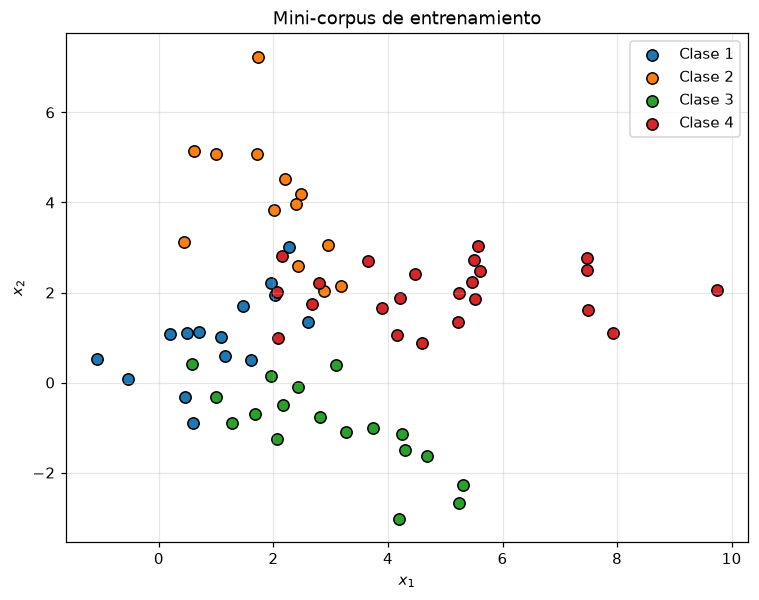

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
for c in clases:
    ax.scatter(*X[y == c].T, color=colores_clase[c], edgecolor="k", s=55, label=f"Clase {c}")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Mini-corpus de entrenamiento")
ax.legend()
plt.show()

### 3.3 Estimación de parámetros y construcción del clasificador

In [12]:
clf = ClasificadorGaussiano.desde_datos(X, y, ddof=0)

np.set_printoptions(precision=3, suppress=True)
for i, c in enumerate(clases):
    print(f"Clase {c}:  P = {clf.prior[i]:.3f}   mu = {clf.mu[i]}")
    print(f"           Sigma = {clf.Sigma[i].tolist()}")

Clase 1:  P = 0.217   mu = [1. 1.]
           Sigma = [[0.9992978100853154, 0.5945771856208734], [0.5945771856208734, 0.9192720484435933]]
Clase 2:  P = 0.188   mu = [2. 4.]
           Sigma = [[0.7085117943792072, -0.5976844532947336], [-0.5976844532947336, 1.9566195923917162]]
Clase 3:  P = 0.261   mu = [ 3. -1.]
           Sigma = [[2.0011248674345707, -1.0085803367741581], [-1.0085803367741581, 0.8992292838807207]]
Clase 4:  P = 0.333   mu = [5. 2.]
           Sigma = [[3.9801660952302456, 0.09809586888695652], [0.09809586888695652, 0.3804215092173914]]


### 3.4 a) Clasificación del conjunto de entrenamiento

Se clasifican las 69 muestras de entrenamiento y se calcula la **tasa de aciertos** (accuracy) $=\dfrac{\#\text{aciertos}}{N}$. También se calcula la **matriz de confusión** (filas: clase real; columnas: clase predicha) para ver qué clases se confunden.

In [13]:
def matriz_confusion(y_real, y_pred, clases):
    M = np.zeros((len(clases), len(clases)), dtype=int)
    for i, cr in enumerate(clases):
        for j, cp in enumerate(clases):
            M[i, j] = np.sum((y_real == cr) & (y_pred == cp))
    return M


y_pred_train = clf.predecir(X)
acc_train = np.mean(y_pred_train == y)
print(f"Tasa de aciertos (entrenamiento): {acc_train * 100:.2f}%  ({np.sum(y_pred_train == y)}/{len(y)})\n")

M = matriz_confusion(y, y_pred_train, clases)
print("Matriz de confusión (filas = real, columnas = predicha)")
print("        " + " ".join(f"pred {c}" for c in clases))
for c, fila in zip(clases, M):
    print(f"real {c}  " + " ".join(f"{v:>6}" for v in fila))

Tasa de aciertos (entrenamiento): 88.41%  (61/69)

Matriz de confusión (filas = real, columnas = predicha)
        pred 1 pred 2 pred 3 pred 4
real 1      13      1      0      1
real 2       0     11      0      2
real 3       1      0     17      0
real 4       2      1      0     20


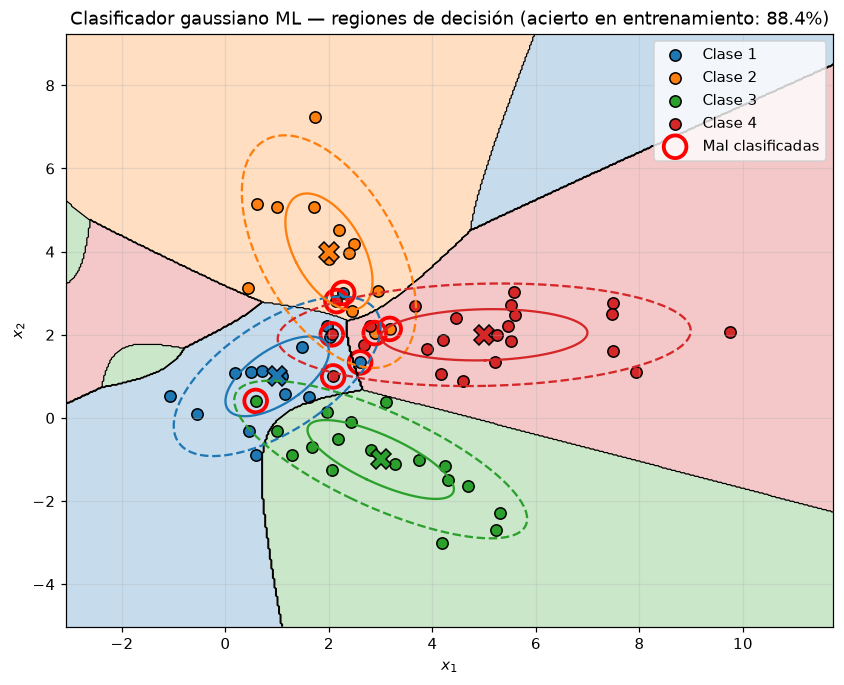

In [14]:
def graficar_regiones(ax, clf, xlim, ylim, n=500):
    xx, yy = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    Z = clf.predecir(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    niveles = np.append(clases - 0.5, clases[-1] + 0.5)
    ax.contourf(xx, yy, Z, levels=niveles, colors=[colores_clase[c] for c in clases], alpha=0.25)
    ax.contour(xx, yy, Z, levels=niveles, colors="k", linewidths=0.8)


xlim3 = (X[:, 0].min() - 2, X[:, 0].max() + 2)
ylim3 = (X[:, 1].min() - 2, X[:, 1].max() + 2)

fig, ax = plt.subplots(figsize=(9, 7))
graficar_regiones(ax, clf, xlim3, ylim3)
for i, c in enumerate(clases):
    ax.scatter(*X[y == c].T, color=colores_clase[c], edgecolor="k", s=55, label=f"Clase {c}")
    for k, ls in zip([1, 2], ["-", "--"]):                      # elipses de 1σ y 2σ de cada clase estimada
        e = elipse_sigma(clf.mu[i], clf.Sigma[i], k)
        ax.plot(e[:, 0], e[:, 1], color=colores_clase[c], ls=ls, lw=1.5)
    ax.plot(*clf.mu[i], "X", color=colores_clase[c], ms=13, mec="k")

err = y_pred_train != y
ax.scatter(*X[err].T, s=220, facecolors="none", edgecolors="red", linewidths=2.5, label="Mal clasificadas")
ax.set_xlim(xlim3); ax.set_ylim(ylim3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(f"Clasificador gaussiano ML — regiones de decisión (acierto en entrenamiento: {acc_train * 100:.1f}%)")
ax.legend(loc="upper right")
plt.show()

### 3.5 b) Datos de prueba generados a partir de los parámetros estimados

El clasificador es un **modelo generativo**: además de clasificar, los parámetros estimados definen una distribución conjunta $p(\mathbf{x},\omega_i)=P(\omega_i)\,\mathcal{N}(\mathbf{x};\hat{\boldsymbol{\mu}}_i,\hat{\boldsymbol{\Sigma}}_i)$ de la que se puede muestrear. El procedimiento es:

1. sortear la clase $\omega_i\sim\hat P(\omega_i)$ (respetando los priors estimados);
2. sortear $\mathbf{x}\sim\mathcal{N}(\hat{\boldsymbol{\mu}}_i,\hat{\boldsymbol{\Sigma}}_i)$.

Estos datos "nuevos" no fueron usados en el ajuste, de modo que sirven como conjunto de prueba. Se hacen dos experimentos:

- **Un conjunto grande** ($N=100\,000$), que da una estimación muy precisa del desempeño *esperado* del modelo.
- **Muchos conjuntos pequeños** del mismo tamaño que el de entrenamiento ($N=69$), para ver cuánto varía la tasa de aciertos de un conjunto a otro y situar en esa distribución el valor obtenido sobre los datos de entrenamiento.

In [15]:
# --- Conjunto grande ---
X_test, y_test = clf.muestrear(100_000, rng)
acc_test = np.mean(clf.predecir(X_test) == y_test)

# --- Muchos conjuntos pequeños (tamaño = entrenamiento) ---
n_rep = 2000
acc_pequenos = np.empty(n_rep)
for r in range(n_rep):
    Xs, ys = clf.muestrear(len(X), rng)
    acc_pequenos[r] = np.mean(clf.predecir(Xs) == ys)

print(f"Aciertos sobre entrenamiento (N = {len(X)})             : {acc_train * 100:.2f}%")
print(f"Aciertos sobre datos sintéticos (N = 100 000)        : {acc_test * 100:.2f}%")
print(f"Aciertos sobre {n_rep} conjuntos sintéticos de N = {len(X)}: "
      f"{acc_pequenos.mean() * 100:.2f}% ± {acc_pequenos.std() * 100:.2f}%  (media ± desvío)")
print(f"Fracción de conjuntos pequeños con acierto <= entrenamiento: {np.mean(acc_pequenos <= acc_train) * 100:.1f}%")

Aciertos sobre entrenamiento (N = 69)             : 88.41%
Aciertos sobre datos sintéticos (N = 100 000)        : 87.13%
Aciertos sobre 2000 conjuntos sintéticos de N = 69: 87.00% ± 3.99%  (media ± desvío)
Fracción de conjuntos pequeños con acierto <= entrenamiento: 68.5%


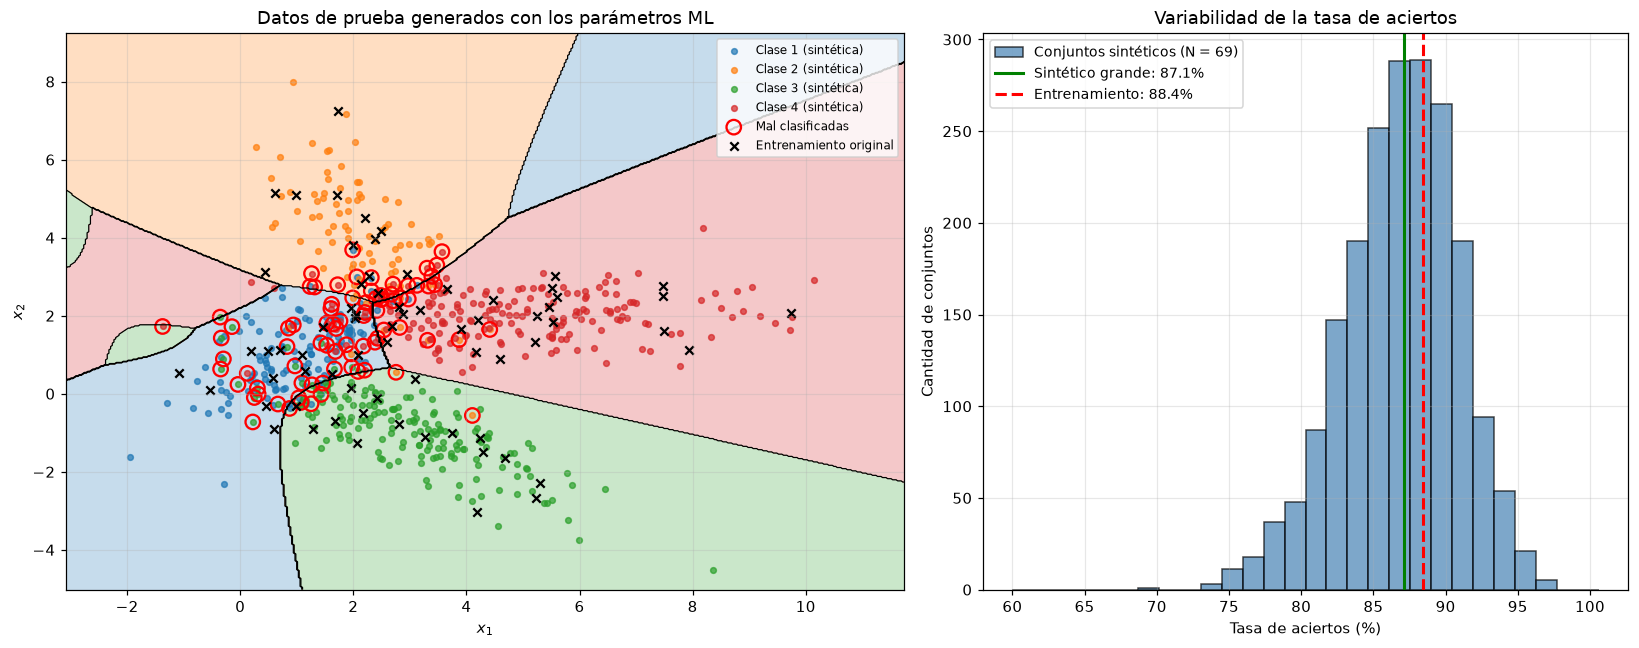

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})

# --- Izquierda: datos de prueba sintéticos sobre las regiones de decisión ---
Xp, yp = clf.muestrear(600, rng)                       # 600 puntos para que el gráfico sea legible
graficar_regiones(ax1, clf, xlim3, ylim3)
for c in clases:
    ax1.scatter(*Xp[yp == c].T, color=colores_clase[c], s=14, alpha=0.7, label=f"Clase {c} (sintética)")
ok_p = clf.predecir(Xp) == yp
ax1.scatter(*Xp[~ok_p].T, s=90, facecolors="none", edgecolors="red", linewidths=1.5, label="Mal clasificadas")
ax1.scatter(*X.T, c="k", marker="x", s=30, label="Entrenamiento original")
ax1.set_xlim(xlim3); ax1.set_ylim(ylim3)
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$")
ax1.set_title("Datos de prueba generados con los parámetros ML")
ax1.legend(fontsize=8, loc="upper right")

# --- Derecha: variabilidad de la tasa de aciertos en conjuntos de N = 69 ---
ax2.hist(acc_pequenos * 100, bins=np.arange(60, 101.5, 1.45), color="steelblue", edgecolor="k", alpha=0.7,
         label=f"Conjuntos sintéticos (N = {len(X)})")
ax2.axvline(acc_test * 100, color="green", lw=2, label=f"Sintético grande: {acc_test * 100:.1f}%")
ax2.axvline(acc_train * 100, color="red", lw=2, ls="--", label=f"Entrenamiento: {acc_train * 100:.1f}%")
ax2.set_xlabel("Tasa de aciertos (%)"); ax2.set_ylabel("Cantidad de conjuntos")
ax2.set_title("Variabilidad de la tasa de aciertos")
ax2.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

#### Matriz de confusión sobre el conjunto de prueba grande

In [17]:
M_test = matriz_confusion(y_test, clf.predecir(X_test), clases)
print("Matriz de confusión normalizada por fila (% de cada clase real), conjunto sintético grande")
print("        " + " ".join(f"pred {c}" for c in clases))
for c, fila in zip(clases, M_test):
    print(f"real {c}  " + " ".join(f"{v / fila.sum() * 100:5.1f}%" for v in fila))

Matriz de confusión normalizada por fila (% de cada clase real), conjunto sintético grande
        pred 1 pred 2 pred 3 pred 4
real 1   84.8%   4.7%   4.7%   5.8%
real 2    5.2%  84.0%   0.5%  10.4%
real 3   10.3%   0.0%  89.4%   0.3%
real 4    8.1%   3.0%   0.3%  88.6%


**Observaciones.**

- **Entrenamiento.** El clasificador acierta 61 de las 69 muestras (**88.4 %**). Los 8 errores se concentran en la zona central, donde se encuentran las clases 1, 2 y 4 y sus elipses se solapan (las clases 1 y 3, y 2 y 4, son vecinas). La clase 3 es la mejor separada, con un solo error.
- **Datos sintéticos.** Sobre 100 000 muestras generadas con los parámetros ML la tasa de aciertos es de **87.1 %**, muy similar a la del entrenamiento (88.4 %). La matriz de confusión normalizada muestra el mismo patrón: cada clase se clasifica correctamente entre el 84 % y el 89 % de las veces, y los errores se dan entre clases vecinas.
- **Variabilidad.** Con conjuntos del tamaño del original ($N=69$) la tasa de aciertos fluctúa en torno a $87.0\pm4.0\,\%$ de un conjunto a otro. El 88.4 % del entrenamiento cae en el centro de esa distribución (el 68.5 % de los conjuntos sintéticos tiene un acierto menor o igual), por lo que la diferencia de ~1.3 puntos con el valor esperado **no es significativa**: no hay evidencia de sobreajuste. Que el entrenamiento sea apenas mejor es lo esperable, ya que los parámetros se ajustaron justamente a esos puntos.

> **Alcance de la comparación.** Los datos de prueba salen del *propio modelo*, de modo que 87.1 % es la tasa de aciertos *esperada si los datos realmente fueran gaussianos con estos parámetros*. Es un chequeo de consistencia (el modelo se comporta en datos nuevos como en los de entrenamiento), pero no mide la robustez frente a datos reales que se aparten de la normalidad, ni el error de estimación de los parámetros con apenas 13 a 23 muestras por clase. Para eso haría falta un conjunto de prueba real (o validación cruzada).

### 3.6 Extra: ¿hace falta la covarianza por clase?

Para conectar con la tabla de casos de la sección 2.1, se comparan sobre los mismos datos de entrenamiento:

- **Caso 1** — $\boldsymbol{\Sigma}_i=\sigma^2\mathbf{I}$, con $\sigma^2$ la varianza promedio de todas las clases;
- **Caso 2** — $\boldsymbol{\Sigma}_i=\boldsymbol{\Sigma}$, con $\boldsymbol{\Sigma}=\sum_i\hat P(\omega_i)\hat{\boldsymbol{\Sigma}}_i$ (covarianza *agrupada*);
- **Caso 3** — $\hat{\boldsymbol{\Sigma}}_i$ propia de cada clase (el modelo ajustado arriba).

Los tres usan las mismas medias y priors estimados; solo cambia la estructura de la covarianza. Notar que se evalúa sobre los datos de entrenamiento, por lo que el caso 3, que tiene más parámetros, parte con ventaja; aun así sirve para ver cómo cambia la forma de las fronteras.

Caso 1  acierto en entrenamiento: 85.51%  (59/69)
Caso 2  acierto en entrenamiento: 85.51%  (59/69)
Caso 3  acierto en entrenamiento: 88.41%  (61/69)


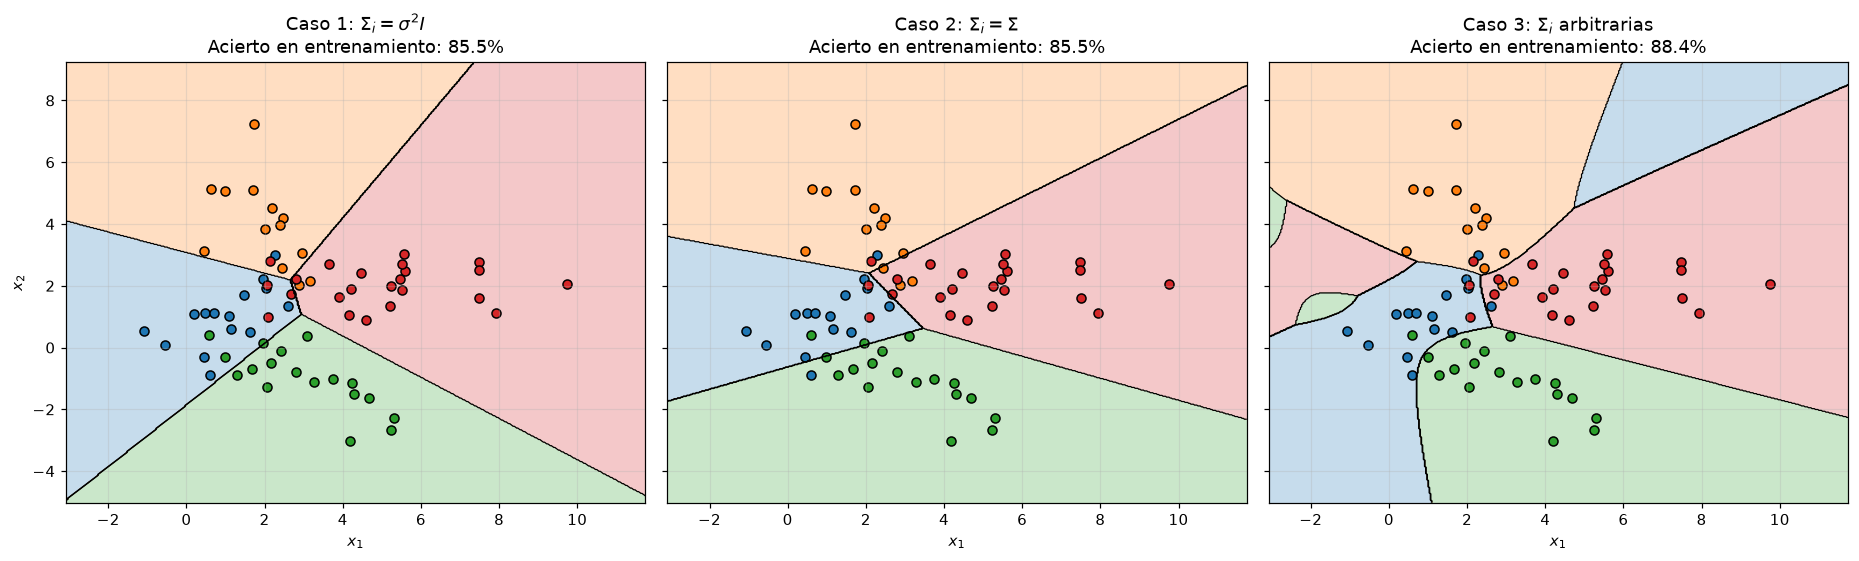

Estimador insesgado (ddof=1) para la covarianza del caso 3:
  acierto en entrenamiento: 88.41%  (ML, ddof=0: 88.41%)


In [18]:
Sigma_agrupada = np.einsum("i,ijk->jk", clf.prior, clf.Sigma)       # sum_i P_i Sigma_i
sigma2 = np.trace(Sigma_agrupada) / X.shape[1]                       # varianza promedio por dimensión

casos = {
    "Caso 1: $\\Sigma_i=\\sigma^2 I$": ClasificadorGaussiano(clf.mu, [sigma2 * np.eye(2)] * C, clf.prior, clases),
    "Caso 2: $\\Sigma_i=\\Sigma$": ClasificadorGaussiano(clf.mu, [Sigma_agrupada] * C, clf.prior, clases),
    "Caso 3: $\\Sigma_i$ arbitrarias": clf,
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
for ax, (nombre, modelo) in zip(axes, casos.items()):
    acc = np.mean(modelo.predecir(X) == y)
    print(f"{nombre.split(':')[0]:<7} acierto en entrenamiento: {acc * 100:.2f}%  ({int(round(acc * len(y)))}/{len(y)})")
    graficar_regiones(ax, modelo, xlim3, ylim3)
    for c in clases:
        ax.scatter(*X[y == c].T, color=colores_clase[c], edgecolor="k", s=35)
    ax.set_xlim(xlim3); ax.set_ylim(ylim3)
    ax.set_xlabel("$x_1$")
    ax.set_title(f"{nombre}\nAcierto en entrenamiento: {acc * 100:.1f}%")
axes[0].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

print("Estimador insesgado (ddof=1) para la covarianza del caso 3:")
clf_ins = ClasificadorGaussiano.desde_datos(X, y, ddof=1)
print(f"  acierto en entrenamiento: {np.mean(clf_ins.predecir(X) == y) * 100:.2f}%  "
      f"(ML, ddof=0: {acc_train * 100:.2f}%)")

**Observaciones.**

- Los casos 1 y 2 aciertan lo mismo (85.5 %, 59/69) y producen **fronteras rectas** (poligonales); el caso 3 mejora a 88.4 % (61/69) y las curva, porque puede adaptarse a la forma de cada nube: por ejemplo, la clase 4 está muy alargada a lo largo de $x_1$ (varianza $\approx 4.0$ frente a $0.38$ en $x_2$) y la clase 3 tiene correlación negativa. Con solo 69 puntos la ventaja de 2 aciertos es modesta y no puede considerarse concluyente, pero es coherente con la geometría de los datos.
- La comparación con el estimador insesgado ($N_i-1$) da exactamente el mismo acierto que el ML, como se anticipó: la diferencia entre ambos estimadores es un factor $N_i/(N_i-1)$ en $\hat{\boldsymbol{\Sigma}}_i$ que apenas desplaza las fronteras.
- **Advertencia sobre las fronteras cuádricas.** En el caso 3 aparecen regiones "fantasma" lejos de los datos (el pequeño sector verde y rojo a la izquierda, o el azul arriba a la derecha). Son el resultado de extrapolar las cuádricas: lejos de las muestras el orden entre discriminantes lo decide el término cuadrático, que puede favorecer a una clase poco razonable. No afectan a los datos observados, pero muestran que el modelo flexible es poco confiable fuera del soporte de entrenamiento.

---
## 4. Conclusiones

1. **Clasificador lineal.** Con discriminantes lineales las fronteras son rectas $g_i=g_j$ y las regiones, cuñas convexas. Las tres fronteras concurren en $(0.5,\,0)$ y solo cuenta, de cada recta, la semirrecta donde el empate es el máximo. Los puntos $(2,1)$, $(2,-1)$, $(-1,1)$ y $(-1,-1)$ se clasifican en $\omega_2$, $\omega_3$, $\omega_1$ y $\omega_1$, respectivamente.
2. **Clasificador gaussiano de Bayes.** Con $\boldsymbol{\Sigma}=\mathbf{I}$ y priors iguales, la regla óptima es la de mínima distancia euclídea y la frontera es la mediatriz $x_1=x_2$. La probabilidad a posteriori es una sigmoide de la distancia a la frontera, y el error de Bayes teórico $\Phi(-\Delta/2)\approx1.7\,\%$ se verificó por simulación (1.71 %). Es el mejor error posible para estas distribuciones.
3. **Estimación ML y modelo generativo.** Los parámetros $\hat{\boldsymbol{\mu}}_i$, $\hat{\boldsymbol{\Sigma}}_i$ y $\hat P(\omega_i)$ se obtienen en forma cerrada a partir de las muestras. El clasificador resultante acierta 88.4 % en entrenamiento y 87.1 % en datos sintéticos, resultados consistentes entre sí dentro de la variabilidad esperada para $N=69$. Esa consistencia vale *bajo el supuesto de normalidad* que sostiene al modelo.
4. **Estructura de la covarianza.** Permitir una covarianza por clase (caso 3) ajusta mejor a nubes de distinta forma y orientación, a costa de más parámetros a estimar y de fronteras cuadráticas poco confiables lejos de los datos. Los modelos más simples (casos 1 y 2) dan fronteras lineales más estables.